In [ ]:
import os
import matplotlib.pyplot as plt
from IPython.display import display

# Create a folder for all plots
os.makedirs("analytics_plots", exist_ok=True)

plot_count = 0
_original_show = plt.show

def save_and_show(*args, **kwargs):
    global plot_count

    for fig_num in plt.get_fignums():
        fig = plt.figure(fig_num)
        plot_count += 1

        fig.savefig(
            f"analytics_plots/plot_{plot_count:02d}.png",
            dpi=300,
            bbox_inches="tight"
        )

    _original_show(*args, **kwargs)

plt.show = save_and_show

In [ ]:
import pandas as pd
import os
from sqlalchemy import create_engine
import logging
import time

logging.basicConfig(
    filename="/content/ingestion_db.log",
    level=logging.DEBUG,
    format="%(asctime)s - %(levelname)s - %(message)s",
    filemode="a",
    force=True
)

engine = create_engine('sqlite:///inventory.db')


def ingest_db(df, table_name, engine):
    df.to_sql(table_name, con=engine, if_exists='replace', index=False)


def load_raw_data():

    start_time = time.time()

    for file in os.listdir('/content'):

        if '.csv' in file:

            print(file)

            df = pd.read_csv('/content/' + file)

            logging.info(f'Ingesting {file} in db')

            print(df.shape)

            ingest_db(df, file[:-4], engine)

    end_time = time.time()

    total_time = (end_time - start_time) / 60

    logging.info("Ingestion Complete")
    logging.info(f"Total time taken = {total_time} minutes")


if __name__ == "__main__":
    load_raw_data()

begin_inventory.csv
(12577, 9)
purchase_prices.csv
(12261, 9)
purchases.csv
(48341, 16)
sales.csv
(8294, 14)
end_inventory.csv
(12573, 9)
vendor_invoice.csv
(5543, 10)


In [ ]:
import pandas as pd
import sqlite3
conn = sqlite3.connect('inventory.db')


In [ ]:
tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'",conn)
tables
"""sqlite_master is a special SQLite system table that stores information about the database structure.
It has columns such as:
type
name
tbl_name
rootpage
sql """

'sqlite_master is a special SQLite system table that stores information about the database structure.\nIt has columns such as:\ntype\nname\ntbl_name\nrootpage\nsql '

In [ ]:
# from google.colab import sheets
# sheet = sheets.InteractiveSheet(df=tables)

In [ ]:
for table in tables['name']:
  print('-'*50, f"{table}", "-"*50)
  print("Count of records: ",pd.read_sql(f"SELECT count(*) as count FROM {table}",conn)['count'].values[0])
  display(pd.read_sql(f"select * from {table} limit 5",conn))

-------------------------------------------------- begin_inventory --------------------------------------------------
Count of records:  12577


,InventoryId,Store,City,Brand,Description,Size,onHand,Price,startDate
0,1_HARDERSFIELD_58,1,HARDERSFIELD,58,Gekkeikan Black & Gold Sake,750mL,8.0,12.99,2024-01-01
1,1_HARDERSFIELD_60,1,HARDERSFIELD,60,Canadian Club 1858 VAP,750mL,7.0,10.99,2024-01-01
2,1_HARDERSFIELD_62,1,HARDERSFIELD,62,Herradura Silver Tequila,750mL,6.0,36.99,2024-01-01
3,1_HARDERSFIELD_63,1,HARDERSFIELD,63,Herradura Reposado Tequila,750mL,3.0,38.99,2024-01-01
4,1_HARDERSFIELD_72,1,HARDERSFIELD,72,No. 3 London Dry Gin,750mL,6.0,34.99,2024-01-01


-------------------------------------------------- purchase_prices --------------------------------------------------
Count of records:  12261


,Brand,Description,Price,Size,Volume,Classification,PurchasePrice,VendorNumber,VendorName
0,58,Gekkeikan Black & Gold Sake,12.99,750mL,750,1,9.28,8320,SHAW ROSS INT L IMP LTD
1,62,Herradura Silver Tequila,36.99,750mL,750,1,28.67,1128,BROWN-FORMAN CORP
2,63,Herradura Reposado Tequila,38.99,750mL,750,1,30.46,1128,BROWN-FORMAN CORP
3,72,No. 3 London Dry Gin,34.99,750mL,750,1,26.11,9165,ULTRA BEVERAGE COMPANY LLP
4,75,Three Olives Tomato Vodka,14.99,750mL,750,1,10.94,7245,PROXIMO SPIRITS INC.


-------------------------------------------------- purchases --------------------------------------------------
Count of records:  48341


...

,InventoryId,Store,Brand,Description,Size,SalesQuantity,SalesDollars,SalesPrice,SalesDate,Volume,Classification,ExciseTax,VendorNo,VendorName
0,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,16.49,16.49,2024-01-01,750.0,1.0,0.79,12546.0,JIM BEAM BRANDS COMPANY
1,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,2,32.98,16.49,2024-01-02,750.0,1.0,1.57,12546.0,JIM BEAM BRANDS COMPANY
2,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,16.49,16.49,2024-01-03,750.0,1.0,0.79,12546.0,JIM BEAM BRANDS COMPANY
3,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,14.49,14.49,2024-01-08,750.0,1.0,0.79,12546.0,JIM BEAM BRANDS COMPANY
4,1_HARDERSFIELD_1005,1,1005,Maker's Mark Combo Pack,375mL 2 Pk,2,69.98,34.99,2024-01-09,375.0,1.0,0.79,12546.0,JIM BEAM BRANDS COMPANY


-------------------------------------------------- end_inventory --------------------------------------------------
Count of records:  12573


,InventoryId,Store,City,Brand,Description,Size,onHand,Price,endDate
0,1_HARDERSFIELD_58,1,HARDERSFIELD,58,Gekkeikan Black & Gold Sake,750mL,11.0,12.99,2024-12-31
1,1_HARDERSFIELD_62,1,HARDERSFIELD,62,Herradura Silver Tequila,750mL,7.0,36.99,2024-12-31
2,1_HARDERSFIELD_63,1,HARDERSFIELD,63,Herradura Reposado Tequila,750mL,7.0,38.99,2024-12-31
3,1_HARDERSFIELD_72,1,HARDERSFIELD,72,No. 3 London Dry Gin,750mL,4.0,34.99,2024-12-31
4,1_HARDERSFIELD_75,1,HARDERSFIELD,75,Three Olives Tomato Vodka,750mL,7.0,14.99,2024-12-31


-------------------------------------------------- vendor_invoice --------------------------------------------------
Count of records:  5543


,VendorNumber,VendorName,InvoiceDate,PONumber,PODate,PayDate,Quantity,Dollars,Freight,Approval
0,105,ALTAMAR BRANDS LLC,2024-01-04,8124,2023-12-21,2024-02-16,6,214.26,3.47,None
1,4466,AMERICAN VINTAGE BEVERAGE,2024-01-07,8137,2023-12-22,2024-02-21,15,140.55,8.57,None
2,388,ATLANTIC IMPORTING COMPANY,2024-01-09,8169,2023-12-24,2024-02-16,5,106.60,4.61,None
3,480,BACARDI USA INC,2024-01-12,8106,2023-12-20,2024-02-05,10100,137483.78,2935.20,None
4,516,BANFI PRODUCTS CORP,2024-01-07,8170,2023-12-24,2024-02-12,1935,15527.25,429.20,None


In [ ]:
purchases = pd.read_sql_query("select * from purchases where VendorNumber = 1128",conn)
purchases

,InventoryId,Store,Brand,Description,Size,VendorNumber,VendorName,PONumber,PODate,ReceivingDate,InvoiceDate,PayDate,PurchasePrice,Quantity,Dollars,Classification
0,54_GUTHRAM_5075,54,5075,Tuaca Italian Liqueur,750mL,1128,BROWN-FORMAN CORP,8150.0,2023-12-23,2024-01-02,2024-01-09,2024-02-19,15.03,12.0,180.36,1.0
1,1_HARDERSFIELD_1232,1,1232,Jack Daniels No 7 Black,750mL,1128,BROWN-FORMAN CORP,8150.0,2023-12-23,2024-01-01,2024-01-09,2024-02-19,15.93,36.0,573.48,1.0
2,47_PELLA'S WISH_1232,47,1232,Jack Daniels No 7 Black,750mL,1128,BROWN-FORMAN CORP,8150.0,2023-12-23,2024-01-02,2024-01-09,2024-02-19,15.93,10.0,159.30,1.0
3,15_WANBORNE_1867,15,1867,Jack Daniels Tennessee Honey,50mL,1128,BROWN-FORMAN CORP,8150.0,2023-12-23,2024-01-01,2024-01-09,2024-02-19,2.15,119.0,255.85,1.0
4,15_WANBORNE_8342,15,8342,Korbel X Dry,750mL,1128,BROWN-FORMAN CORP,8150.0,2023-12-23,2024-01-01,2024-01-09,2024-02-19,8.21,15.0,123.15,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1541,30_CULCHETH_1545,30,1545,Gentleman Jack,750mL,1128,BROWN-FORMAN CORP,8210.0,2023-12-27,2024-01-07,2024-01-15,2024-02-25,19.42,12.0,233.04,1.0
1542,45_VERITAS_1232,45,1232,Jack Daniels No 7 Black,750mL,1128,BROWN-FORMAN CORP,8210.0,2023-12-27,2024-01-06,2024-01-15,2024-02-25,15.93,11.0,175.23,1.0
1543,38_GOULCREST_1770,38,1770,Jack Daniels Tennessee Fire,1.75L,1128,BROWN-FORMAN CORP,8210.0,2023-12-27,2024-01-07,2024-01-15,2024-02-25,26.42,6.0,158.52,1.0
1544,74_PAENTMARWY_2760,74,2760,Jack Daniels Tennessee Honey,1.75L,1128,BROWN-FORMAN CORP,8210.0,2023-12-27,2024-01-08,2024-01-15,2024-02-25,28.02,2.0,56.04,1.0


In [ ]:
purchase_prices = pd.read_sql_query("select * from purchase_prices where VendorNumber = 1128",conn)
purchase_prices

,Brand,Description,Price,Size,Volume,Classification,PurchasePrice,VendorNumber,VendorName
0,62,Herradura Silver Tequila,36.99,750mL,750,1,28.67,1128,BROWN-FORMAN CORP
1,63,Herradura Reposado Tequila,38.99,750mL,750,1,30.46,1128,BROWN-FORMAN CORP
2,171,Gentleman Jack,49.99,1750mL,1750,1,36.76,1128,BROWN-FORMAN CORP
3,809,Southern Comfort,17.99,1000mL,1000,1,13.13,1128,BROWN-FORMAN CORP
4,811,Jack Daniels No 7 Black,29.99,1000mL,1000,1,19.84,1128,BROWN-FORMAN CORP
...,...,...,...,...,...,...,...,...,...
137,1260,Old Forester Birthday 2016,89.99,750mL,750,1,71.99,1128,BROWN-FORMAN CORP
138,1279,Woodford Rsv MC Brandy Fnish,99.99,750mL,750,1,77.51,1128,BROWN-FORMAN CORP
139,1801,Jack Daniels Tennesse Fire,12.99,375mL,375,1,9.62,1128,BROWN-FORMAN CORP
140,2033,Canadian Mist,7.99,750mL,750,1,5.96,1128,BROWN-FORMAN CORP


In [ ]:
vendor_invoice = pd.read_sql_query("select * from vendor_invoice where VendorNumber = 1128",conn)
vendor_invoice

,VendorNumber,VendorName,InvoiceDate,PONumber,PODate,PayDate,Quantity,Dollars,Freight,Approval
0,1128,BROWN-FORMAN CORP,2024-01-09,8150,2023-12-23,2024-02-19,4684,65403.57,1808.77,None
1,1128,BROWN-FORMAN CORP,2024-01-15,8210,2023-12-27,2024-02-25,23351,298902.89,1494.51,Frank Delahunt
2,1128,BROWN-FORMAN CORP,2024-01-26,8358,2024-01-06,2024-02-18,11443,138035.44,690.18,None
3,1128,BROWN-FORMAN CORP,2024-02-02,8457,2024-01-13,2024-02-29,12899,142492.97,755.21,None
4,1128,BROWN-FORMAN CORP,2024-02-06,8517,2024-01-18,2024-03-15,23217,335055.84,1708.78,Frank Delahunt
5,1128,BROWN-FORMAN CORP,2024-02-15,8689,2024-01-29,2024-03-24,18863,250689.87,1328.66,Frank Delahunt
6,1128,BROWN-FORMAN CORP,2024-02-23,8742,2024-02-02,2024-03-17,11876,165219.61,743.49,None
7,1128,BROWN-FORMAN CORP,2024-02-23,8838,2024-02-09,2024-03-25,17574,203550.59,956.69,None
8,1128,BROWN-FORMAN CORP,2024-03-02,8945,2024-02-16,2024-04-11,27342,313177.52,1691.16,Frank Delahunt
9,1128,BROWN-FORMAN CORP,2024-03-07,9017,2024-02-21,2024-04-21,15019,195521.15,1036.26,None


In [ ]:
sales = pd.read_sql_query("select * from sales where VendorNo = 1128",conn)
sales

,InventoryId,Store,Brand,Description,Size,SalesQuantity,SalesDollars,SalesPrice,SalesDate,Volume,Classification,ExciseTax,VendorNo,VendorName
0,1_HARDERSFIELD_1051,1,1051,Woodford Reserve MC 1838,750mL,1,99.99,99.99,2024-01-04,750.0,1.0,0.79,1128.0,BROWN-FORMAN CORP
1,1_HARDERSFIELD_1051,1,1051,Woodford Reserve MC 1838,750mL,1,99.99,99.99,2024-01-23,750.0,1.0,0.79,1128.0,BROWN-FORMAN CORP
2,1_HARDERSFIELD_1060,1,1060,Jack Daniels Bruins Glass Pk,Liter,2,55.98,27.99,2024-01-01,1000.0,1.0,2.10,1128.0,BROWN-FORMAN CORP
3,1_HARDERSFIELD_1060,1,1060,Jack Daniels Bruins Glass Pk,Liter,1,27.99,27.99,2024-01-02,1000.0,1.0,1.05,1128.0,BROWN-FORMAN CORP
4,1_HARDERSFIELD_1060,1,1060,Jack Daniels Bruins Glass Pk,Liter,1,31.99,31.99,2024-01-11,1000.0,1.0,1.05,1128.0,BROWN-FORMAN CORP
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
286,1_HARDERSFIELD_2760,1,2760,Jack Daniels Tennessee Honey,1.75L,2,77.98,38.99,2024-01-30,1750.0,1.0,3.67,1128.0,BROWN-FORMAN CORP
287,1_HARDERSFIELD_30735,1,30735,Sonoma-Cutrer Cutrer V Chard,750mL,1,28.99,28.99,2024-01-30,750.0,2.0,0.11,1128.0,BROWN-FORMAN CORP
288,1_HARDERSFIELD_3314,1,3314,El Jimador Blanco Tequila,1.75L,2,53.98,26.99,2024-01-02,1750.0,1.0,3.67,1128.0,BROWN-FORMAN CORP
289,1_HARDERSFIELD_3314,1,3314,El Jimador Blanco Tequila,1.75L,1,29.99,29.99,2024-01-13,1750.0,1.0,1.84,1128.0,BROWN-FORMAN CORP


In [ ]:
purchases.groupby(['Brand','PurchasePrice'])[['Quantity', 'Dollars']].sum()

,,Quantity,Dollars
Brand,PurchasePrice,,
62,28.67,90.0,2580.30
63,30.46,66.0,2010.36
171,36.76,201.0,7388.76
370,10.36,15.0,155.40
809,13.13,72.0,945.36
...,...,...,...
16828,8.66,284.0,2459.44
26949,15.53,96.0,1490.88
27138,10.80,6.0,64.80


In [ ]:
vendor_invoice['PONumber'].nunique()
vendor_invoice.columns


Index(['VendorNumber', 'VendorName', 'InvoiceDate', 'PONumber', 'PODate',
       'PayDate', 'Quantity', 'Dollars', 'Freight', 'Approval'],
      dtype='object')

In [ ]:
sales.groupby(['Brand'])[['SalesDollars','SalesPrice','SalesQuantity']].sum()

,SalesDollars,SalesPrice,SalesQuantity
Brand,,,
171,699.86,149.97,14
1051,199.98,199.98,2
1060,211.93,183.94,7
1064,45.98,45.98,2
1220,594.83,349.90,17
1231,402.69,207.84,31
1232,1571.32,486.79,68
1233,3599.00,647.82,100
1237,99.98,99.98,2


In [ ]:
freight_summary = pd.read_sql_query("select VendorNumber,SUM(Freight) as FreightCost From vendor_invoice group by VendorNumber",conn)
freight_summary

,VendorNumber,FreightCost
0,2,27.08
1,54,0.48
2,60,367.52
3,105,62.39
4,200,6.19
...,...,...
121,98450,856.02
122,99166,130.09
123,172662,178.34
124,173357,202.50


In [ ]:
pd.read_sql_query("""SELECT
    p.VendorNumber,
    p.VendorName,
    p.Brand,
    p.PurchasePrice,
    pp.Volume,
    pp.Price as ActualPrice,
    SUM(p.Quantity) AS TotalPurchaseQuantity,
    SUM(p.Dollars) AS TotalPurchaseDollars
FROM purchases p
JOIN purchase_prices pp
ON p.Brand = pp.Brand where p.PurchasePrice > 0 Group by p.VendorNumber,
    p.VendorName,
    p.Brand order by TotalPurchaseDollars""",conn)

,VendorNumber,VendorName,Brand,PurchasePrice,Volume,ActualPrice,TotalPurchaseQuantity,TotalPurchaseDollars
0,8664,"STOLI GROUP,(USA) LLC",3147,0.71,50,0.99,1.0,0.71
1,4425,MARTIGNETTI COMPANIES,27934,3.37,750,4.99,1.0,3.37
2,3960,DIAGEO NORTH AMERICA INC,1001,4.28,50,5.99,1.0,4.28
3,9165,ULTRA BEVERAGE COMPANY LLP,21691,5.17,750,7.49,1.0,5.17
4,9815,WINE GROUP INC,17954,5.36,750,7.99,1.0,5.36
...,...,...,...,...,...,...,...,...
4020,480,BACARDI USA INC,3858,17.77,750,23.99,5327.0,94660.79
4021,3960,DIAGEO NORTH AMERICA INC,4261,16.17,1750,22.99,6014.0,97246.38
4022,480,BACARDI USA INC,4227,14.17,1750,17.99,8139.0,115329.63
4023,3960,DIAGEO NORTH AMERICA INC,3102,12.94,1750,17.99,9065.0,117301.10


In [ ]:
sales.columns

Index(['InventoryId', 'Store', 'Brand', 'Description', 'Size', 'SalesQuantity',
       'SalesDollars', 'SalesPrice', 'SalesDate', 'Volume', 'Classification',
       'ExciseTax', 'VendorNo', 'VendorName'],
      dtype='object')

In [ ]:
pd.read_sql_query("""SELECT
VendorNo,
Brand,
SUM(SalesDollars) as TotalSalesDollars,
SUM(SalesPrice) as TotalSalesPrice,
SUM(SalesQuantity) as SalesQuantity,
SUM(ExciseTax) as TotalExciseTax
From Sales
Group by VendorNo,
Brand order by TotalSalesDollars
""",conn)

,VendorNo,Brand,TotalSalesDollars,TotalSalesPrice,SalesQuantity,TotalExciseTax
0,NaN,3562,2.97,0.99,3,NaN
1,1392.0,18000,3.99,3.99,1,0.22
2,12546.0,1006,3.99,3.99,1,0.05
3,9819.0,17867,6.99,6.99,1,0.11
4,90024.0,23969,7.99,7.99,1,0.11
...,...,...,...,...,...,...
1448,4425.0,3405,2279.24,569.81,76,139.62
1449,12546.0,1376,2422.94,526.77,106,194.77
1450,17035.0,2585,2558.93,597.75,107,84.25
1451,3960.0,3545,2679.11,543.82,89,163.52


In [ ]:
import time
start = time.time()
final_table = pd.read_sql_query("""
SELECT
    pp.VendorNumber,
    pp.VendorName,
    pp.Description,
    pp.Brand,
    pp.Price AS ActualPrice,
    pp.PurchasePrice,
    pp.Volume,
    SUM(s.SalesQuantity) AS TotalSalesQuantity,
    SUM(s.SalesDollars) AS TotalSalesDollars,
    SUM(s.SalesPrice) AS TotalSalesPrice,
    SUM(s.ExciseTax) AS TotalExciseTax,

    SUM(v1.Quantity) AS TotalPurchaseQuantity,
    SUM(v1.Dollars) AS TotalPurchaseDollars,
    SUM(v1.Freight) AS TotalFreightCost

FROM purchase_prices pp

JOIN sales s
    ON pp.VendorNumber = s.VendorNo
    AND pp.Brand = s.Brand

JOIN vendor_invoice v1
    ON pp.VendorNumber = v1.VendorNumber

GROUP BY
    pp.VendorNumber,
    pp.Brand,
    pp.Price,
    pp.PurchasePrice
""", conn)
end = time.time()



In [ ]:
print(start)
print(end)
print(final_table)

1791562994.6565444
1791562995.686805
      VendorNumber                   VendorName                   Description  \
0              388  ATLANTIC IMPORTING COMPANY      Glendalough Double Barrel   
1              480  BACARDI USA INC                          Grey Goose Vodka   
2              480  BACARDI USA INC                             B & B Dom VAP   
3              480  BACARDI USA INC                     Grey Goose Glass Pack   
4              480  BACARDI USA INC                  Bonnie Rose Spiced Apple   
...            ...                          ...                           ...   
1447         90058  ZORVINO VINEYARDS                      Zorvino Vyds Pearz   
1448         90058  ZORVINO VINEYARDS                 Zorvino Vyds Sangiovese   
1449         90058  ZORVINO VINEYARDS            Zorvino Vyds Mango Magnifico   
1450         90058  ZORVINO VINEYARDS                    Zorvino Vyds Peachez   
1451         98450  Serralles Usa LLC                        Death's Doo

In [ ]:
final_table.dtypes

,0
VendorNumber,int64
VendorName,object
Description,object
Brand,int64
ActualPrice,float64
PurchasePrice,float64
Volume,object
TotalSalesQuantity,int64
TotalSalesDollars,float64
TotalSalesPrice,float64


In [ ]:
final_table.isnull().sum()

,0
VendorNumber,0
VendorName,0
Description,0
Brand,0
ActualPrice,0
PurchasePrice,0
Volume,0
TotalSalesQuantity,0
TotalSalesDollars,0
TotalSalesPrice,0


In [ ]:
final_table['VendorName'].unique()

array(['ATLANTIC IMPORTING COMPANY ', 'BACARDI USA INC            ',
       'BANFI PRODUCTS CORP        ', 'STATE WINE & SPIRITS   ',
       'SAZERAC NORTH AMERICA INC. ', 'BROWN-FORMAN CORP          ',
       'BULLY BOY DISTILLERS       ', 'CONSTELLATION BRANDS INC   ',
       'CASTLE BRANDS CORP.        ', 'VINEYARD BRANDS INC        ',
       'DIAGEO CHATEAU ESTATE WINES', 'VRANKEN AMERICA            ',
       'SOUTHERN WINE & SPIRITS NE ', 'DELICATO VINEYARDS INC     ',
       'BLACK PRINCE DISTILLERY INC', 'DUGGANS DISTILLED PRODUCTS ',
       'DISARONNO INTERNATIONAL LLC', 'EDRINGTON AMERICAS         ',
       'SIDNEY FRANK IMPORTING CO  ', 'E & J GALLO WINERY         ',
       'WILLIAM GRANT & SONS INC   ', 'HEAVEN HILL DISTILLERIES   ',
       'HOOD RIVER DISTILLERS, Inc.', 'DIAGEO NORTH AMERICA INC   ',
       'CHARLES JACQUIN ET CIE INC ', 'MARTIGNETTI COMPANIES',
       'MARTIGNETTI COMPANIES ', 'KLIN SPIRITS LLC           ',
       'KOBRAND CORPORATION        ', 'LATITUDE B

In [ ]:
final_table['Description'].unique()

array(['Glendalough Double Barrel', 'Grey Goose Vodka', 'B & B Dom VAP',
       ..., 'Zorvino Vyds Mango Magnifico', 'Zorvino Vyds Peachez',
       "Death's Door Gin"], dtype=object)

In [ ]:
final_table['Volume'] = final_table['Volume'].astype('float64')
final_table.fillna(0, inplace = True)

In [ ]:
final_table['VendorName']=final_table['VendorName'].str.strip()

In [ ]:
import numpy as np
final_table['TotalSalesQuantity']= final_table['TotalSalesQuantity'].round().astype(int)
final_table['TotalPurchaseQuantity']= (final_table['TotalSalesQuantity']*(1 + np.random.uniform(0.01,0.005,len(final_table)))).round().astype(int)

In [ ]:
np.random.uniform(0.01,0.1,len(final_table))

array([0.0366522 , 0.03725526, 0.06967636, ..., 0.09975394, 0.03250025,
       0.0181408 ])

In [ ]:
final_table['TotalPurchaseQuantity']

,TotalPurchaseQuantity
0,213
1,1166
2,56
3,111
4,111
...,...
1447,332
1448,111
1449,55
1450,55


In [ ]:
final_table['TotalPurchaseDollars'] = (
    final_table['TotalPurchaseQuantity'] * final_table['PurchasePrice']
)

In [ ]:
final_table['TotalPurchaseDollars']

,TotalPurchaseDollars
0,4541.16
1,23483.24
2,1014.16
3,4247.97
4,1196.58
...,...
1447,2241.00
1448,894.66
1449,470.25
1450,364.10


In [ ]:
final_table['GrossProfit'] = final_table['TotalSalesDollars'] - final_table['TotalPurchaseDollars']

In [ ]:
final_table['GrossProfit'].sum()

np.float64(4901570.069999999)

In [ ]:
final_table['ProfitMargin'] = (final_table['GrossProfit']/final_table['TotalSalesDollars']) * 100
final_table['ProfitMargin']

,ProfitMargin
0,26.110500
1,38.369780
2,26.213394
3,33.405916
4,27.431621
...,...
1447,32.022932
1448,34.881724
1449,31.545236
1450,33.733734


In [ ]:
final_table['StockTurnover'] = final_table['TotalSalesQuantity'] / final_table['TotalPurchaseQuantity']
final_table['StockTurnover']

,StockTurnover
0,0.995305
1,0.990566
2,0.982143
3,0.990991
4,0.990991
...,...
1447,0.993976
1448,0.990991
1449,1.000000
1450,1.000000


In [ ]:
final_table['Unitprofit']=final_table['PurchasePrice']/final_table['ActualPrice']
final_table = final_table.drop(columns='Unitprofit')

In [ ]:
final_table['SalesToPurchaseRatio'] = final_table['TotalSalesDollars'] / final_table['TotalPurchaseDollars']
final_table['SalesToPurchaseRatio'].max()

2.578729767769177

In [ ]:
cursor = conn.cursor()
cursor.execute("""CREATE TABLE final_table_3 (
   VendorNumber INT,
   VendorName VARCHAR(100),
   Brand INT,
   Description VARCHAR(100),
   PurchasePrice DECIMAL(10,2),
   ActualPrice DECIMAL(10,2),
   Volume,
   TotalPurchaseQuantity INT,
   TotalPurchaseDollars DECIMAL(15,2),
   TotalSalesQuantity INT,
   TotalSalesDollars DECIMAL(15,2),
   TotalSalesPrice DECIMAL(15,2),
   TotalExciseTax DECIMAL(15,2),
   FreightCost DECIMAL(15,2),
   GrossProfit DECIMAL(15,2),
   ProfitMargin DECIMAL(15,2),
   StockTurnover DECIMAL(15,2),
   SalesToPurchaseRatio DECIMAL(15,2),
   PRIMARY KEY (VendorNumber, Brand)
);""")

In [ ]:
pd.read_sql_query("select * from final_table_3",conn)

,VendorNumber,VendorName,Brand,Description,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,TotalSalesDollars,TotalSalesPrice,TotalExciseTax,FreightCost,GrossProfit,ProfitMargin,StockTurnover,SalesToPurchaseRatio


In [ ]:
final_table.to_sql('final_table_3',conn,if_exists = 'replace', index = False)


1452

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import sqlite3
from scipy.stats import ttest_ind
import scipy.stats as stats
warnings.filterwarnings('ignore')


In [ ]:
df = pd.read_sql_query("select * from final_table_3",conn)
df.head()


,VendorNumber,VendorName,Description,Brand,ActualPrice,PurchasePrice,Volume,TotalSalesQuantity,TotalSalesDollars,TotalSalesPrice,TotalExciseTax,TotalPurchaseQuantity,TotalPurchaseDollars,TotalFreightCost,GrossProfit,ProfitMargin,StockTurnover,SalesToPurchaseRatio
0,388,ATLANTIC IMPORTING COMPANY,Glendalough Double Barrel,2034,32.99,21.32,750.0,212,6145.88,6145.88,167.48,213,4541.16,846.96,1604.72,26.110500,0.995305,1.353372
1,480,BACARDI USA INC,Grey Goose Vodka,126,32.99,20.14,1000.0,1155,38103.45,23587.85,1212.75,1166,23483.24,1160721.51,14620.21,38.369780,0.990566,1.622581
2,480,BACARDI USA INC,B & B Dom VAP,1020,28.99,18.11,750.0,55,1374.45,1374.45,43.45,56,1014.16,89286.27,360.29,26.213394,0.982143,1.355260
3,480,BACARDI USA INC,Grey Goose Glass Pack,1330,49.99,38.27,1750.0,110,6378.90,6378.90,202.40,111,4247.97,178572.54,2130.93,33.405916,0.990991,1.501635
4,480,BACARDI USA INC,Bonnie Rose Spiced Apple,2200,19.99,10.78,750.0,110,1648.90,1648.90,86.90,111,1196.58,178572.54,452.32,27.431621,0.990991,1.378011


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
VendorNumber,1452.0,8896.335399,15138.534912,388.000000,3252.000000,4692.000000,9552.000000,9.845000e+04
Brand,1452.0,14047.643251,10465.378193,115.000000,2908.750000,14702.500000,22026.000000,3.559000e+04
ActualPrice,1452.0,19.388058,15.957613,0.990000,9.990000,14.990000,22.240000,1.899900e+02
PurchasePrice,1452.0,13.068237,11.404481,0.710000,6.585000,9.440000,15.335000,1.397000e+02
Volume,1452.0,885.707989,524.297231,50.000000,750.000000,750.000000,750.000000,5.000000e+03
TotalSalesQuantity,1452.0,714.988292,1138.250604,30.000000,110.000000,330.000000,820.000000,1.545500e+04
TotalSalesDollars,1452.0,10048.374043,15652.927910,219.450000,2459.180000,5371.400000,10994.500000,1.979450e+05
TotalSalesPrice,1452.0,5270.150634,5329.149062,54.450000,1813.762500,3685.445000,6665.175000,4.672442e+04
TotalExciseTax,1452.0,329.015296,1070.020529,2.750000,30.250000,74.250000,200.900000,1.242945e+04
TotalPurchaseQuantity,1452.0,720.300964,1146.264318,30.000000,111.000000,333.000000,827.000000,1.554400e+04


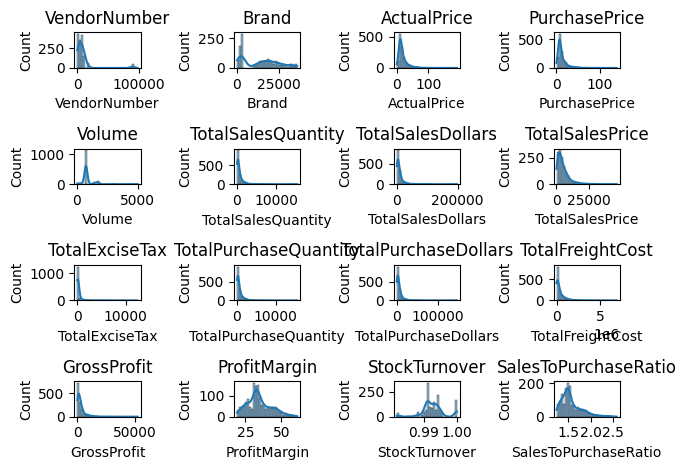

In [ ]:
numerical_cols = df.select_dtypes(include=np.number).columns
for i,col in enumerate(numerical_cols):
    plt.subplot(4,4,i+1)
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(col)
plt.tight_layout()
plt.show()


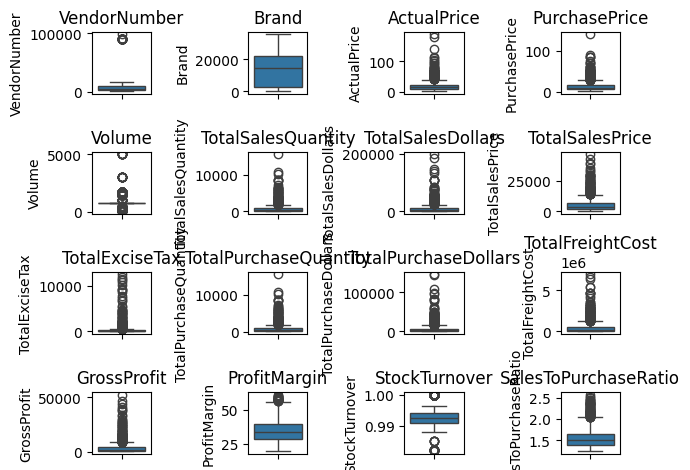

In [ ]:
for i,col in enumerate(numerical_cols):
    plt.subplot(4,4,i+1)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()


In [ ]:
df = pd.read_sql_query("""SELECT * FROM final_table_3 WHERE GrossProfit > 0 AND ProfitMargin > 0 AND TotalSalesQuantity > 0""",conn)

In [ ]:
df


,VendorNumber,VendorName,Description,Brand,ActualPrice,PurchasePrice,Volume,TotalSalesQuantity,TotalSalesDollars,TotalSalesPrice,TotalExciseTax,TotalPurchaseQuantity,TotalPurchaseDollars,TotalFreightCost,GrossProfit,ProfitMargin,StockTurnover,SalesToPurchaseRatio
0,388,ATLANTIC IMPORTING COMPANY,Glendalough Double Barrel,2034,32.99,21.32,750.0,212,6145.88,6145.88,167.48,213,4541.16,846.96,1604.72,26.110500,0.995305,1.353372
1,480,BACARDI USA INC,Grey Goose Vodka,126,32.99,20.14,1000.0,1155,38103.45,23587.85,1212.75,1166,23483.24,1160721.51,14620.21,38.369780,0.990566,1.622581
2,480,BACARDI USA INC,B & B Dom VAP,1020,28.99,18.11,750.0,55,1374.45,1374.45,43.45,56,1014.16,89286.27,360.29,26.213394,0.982143,1.355260
3,480,BACARDI USA INC,Grey Goose Glass Pack,1330,49.99,38.27,1750.0,110,6378.90,6378.90,202.40,111,4247.97,178572.54,2130.93,33.405916,0.990991,1.501635
4,480,BACARDI USA INC,Bonnie Rose Spiced Apple,2200,19.99,10.78,750.0,110,1648.90,1648.90,86.90,111,1196.58,178572.54,452.32,27.431621,0.990991,1.378011
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1447,90058,ZORVINO VINEYARDS,Zorvino Vyds Pearz,22297,9.99,6.75,750.0,330,3296.70,3296.70,36.30,332,2241.00,2692.08,1055.70,32.022932,0.993976,1.471084
1448,90058,ZORVINO VINEYARDS,Zorvino Vyds Sangiovese,22298,12.49,8.06,750.0,110,1373.90,1373.90,12.10,111,894.66,897.36,479.24,34.881724,0.990991,1.535667
1449,90058,ZORVINO VINEYARDS,Zorvino Vyds Mango Magnifico,25125,12.49,8.55,750.0,55,686.95,686.95,6.05,55,470.25,448.68,216.70,31.545236,1.000000,1.460819
1450,90058,ZORVINO VINEYARDS,Zorvino Vyds Peachez,25126,9.99,6.62,750.0,55,549.45,549.45,6.05,55,364.10,448.68,185.35,33.733734,1.000000,1.509063


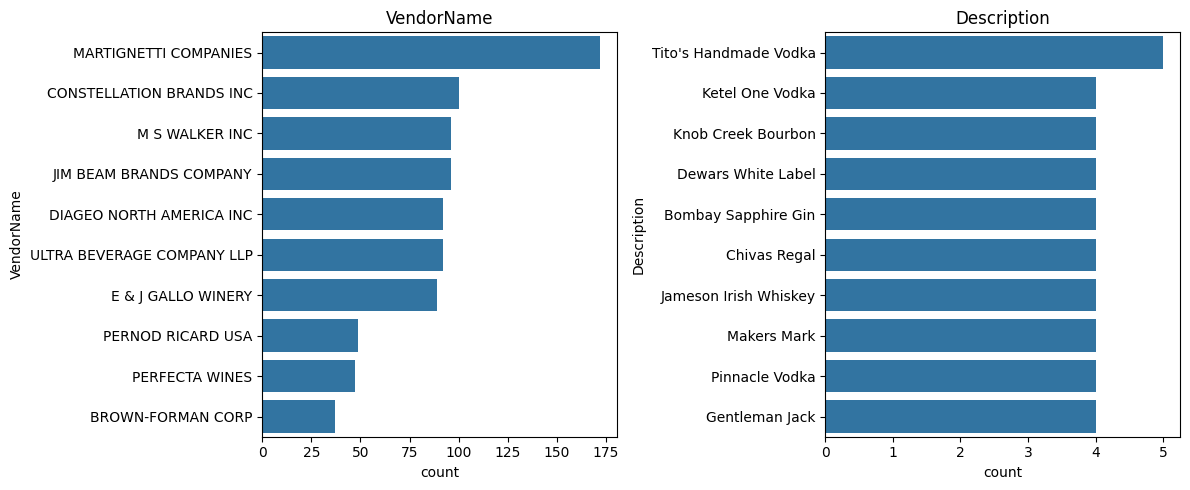

In [ ]:
categorical_cols = ["VendorName","Description"]
plt.figure(figsize=(12,5))
for i,col in enumerate(categorical_cols):
    plt.subplot(1,2,i+1)
    # print(df[col])
    sns.countplot(y=df[col],order =df[col].value_counts().index[:10])
    plt.title(col)
plt.tight_layout()
plt.show()

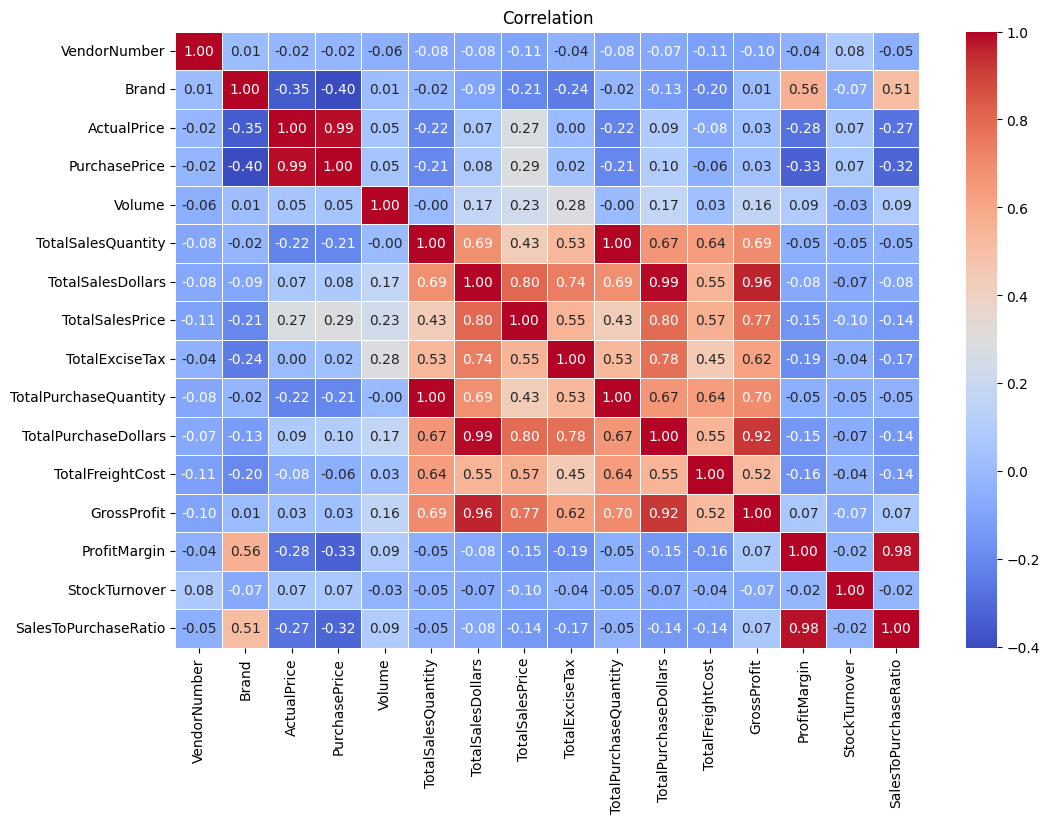

In [ ]:
plt.figure(figsize=(12,8))
correlation_matrix = df[numerical_cols].corr()
sns.heatmap(correlation_matrix, annot = True, fmt='.2f', cmap = "coolwarm" ,linewidths=0.5)
plt.title('Correlation')
plt.show()


Correlation Insights
- PurchasePrice has weak correlations with TotalSalesDollars  and GrossProfit , suggesting that price variations do not significantly impact sales revenue or profit.
- Strong correlation between total purchase quantity and total sales quantity , confirming efficient inventory turnover.
- Negative correlation between profit margin and total sales price  suggests that as sales prices increase, margins decrease, possibly due to competitive pricing pressures.
- StockTurnover has no correlations with both GrossProfit  and ProfitMargin , indicating that faster turnover does not necessarily result in higher profitability.


Identify Brands that needs Promotional adjustmemts which exhibits lower sales but higher profitability


In [ ]:
brand_performance = df.groupby('Description').agg({"TotalSalesDollars":"sum","ProfitMargin":"mean"}).reset_index()
brand_performance

,Description,TotalSalesDollars,ProfitMargin
0,(RI) 1,2034.45,27.223574
1,14 Hands Hot to Trot Red,13902.35,44.881621
2,14 Hands Pinot Grigio,1701.15,42.524763
3,14 Hands Svgn Bl,604.45,47.224750
4,1800 Anejo Tequila,4618.90,35.595055
...,...,...,...
1334,Zorvino Bacca Z Blackberry,769.45,31.660277
1335,Zorvino Vyds Mango Magnifico,686.95,31.545236
1336,Zorvino Vyds Peachez,549.45,33.733734
1337,Zorvino Vyds Pearz,3296.70,32.022932


In [ ]:
low_sales_threshold = brand_performance['TotalSalesDollars'].quantile(0.15)
low_sales_threshold

np.float64(1611.5789999999997)

In [ ]:
high_margin_threshold = brand_performance['ProfitMargin'].quantile(0.85)
high_margin_threshold

np.float64(44.818029080979315)

In [ ]:
target_brands = brand_performance[(brand_performance['TotalSalesDollars']<=low_sales_threshold) & (brand_performance['ProfitMargin'] >= high_margin_threshold)]
print(target_brands.sort_values(by='TotalSalesDollars'))

                       Description  TotalSalesDollars  ProfitMargin
119   Beringer Classic Wh Zin Mosc             384.45     53.934192
871       Nathanson Creek Cab Svgn             549.45     46.346346
829   Middle Sister Drama Queen Pi             549.45     53.953954
536   Fulton's Harvest Apple Pie L             549.45     47.347347
3                 14 Hands Svgn Bl             604.45     47.224750
1009  Ravenswood Vntnrs Blnd Chard             604.45     58.309207
1010  Ravenswood Vntrs Blnd Merlot             604.45     50.227480
838                  Milestone Red             659.45     50.959133
837                Milestone Chard             659.45     50.959133
492   F Coppola Rosso Bianco Pnt G             669.33     46.546547
364       Cono Sur Organic Svgn Bl             695.42     50.375313
35                        Anew Rsl             714.45     48.421863
115       Beringer Classic Moscato             768.90     52.937963
811         Massimo Malbec Mendoza             7

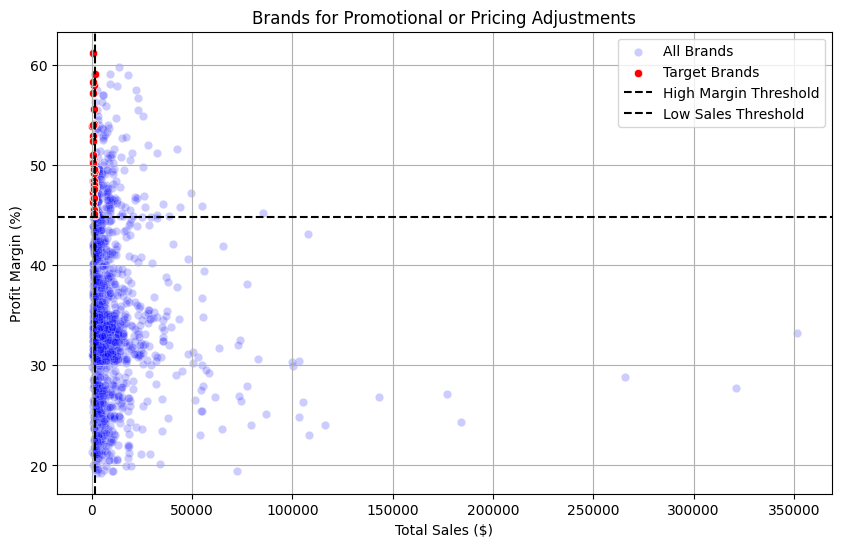

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=brand_performance,
    x='TotalSalesDollars',
    y='ProfitMargin',
    color='blue',
    label='All Brands',
    alpha=0.2
)

sns.scatterplot(
    data=target_brands,
    x='TotalSalesDollars',
    y='ProfitMargin',
    color='red',
    label='Target Brands'
)

plt.axhline(
    high_margin_threshold,
    linestyle='--',
    color='black',
    label='High Margin Threshold'
)

plt.axvline(
    low_sales_threshold,
    linestyle='--',
    color='black',
    label='Low Sales Threshold'
)

plt.xlabel('Total Sales ($)')
plt.ylabel('Profit Margin (%)')
plt.title('Brands for Promotional or Pricing Adjustments')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
top_vendors = df.groupby("VendorName")["TotalSalesDollars"].sum().nlargest(10)
top_brands = df.groupby("Description")["TotalSalesDollars"].sum().nlargest(10)

In [ ]:
top_vendors.index

Index(['MARTIGNETTI COMPANIES', 'JIM BEAM BRANDS COMPANY',
       'DIAGEO NORTH AMERICA INC', 'CONSTELLATION BRANDS INC',
       'E & J GALLO WINERY', 'ULTRA BEVERAGE COMPANY LLP', 'BROWN-FORMAN CORP',
       'M S WALKER INC', 'PERNOD RICARD USA', 'WINE GROUP INC'],
      dtype='object', name='VendorName')

In [ ]:
top_brands.values

array([351415.1 , 320999.25, 265648.9 , 184255.5 , 177010.35, 143114.4 ,
       116339.85, 108172.35, 107921.84, 105197.95])

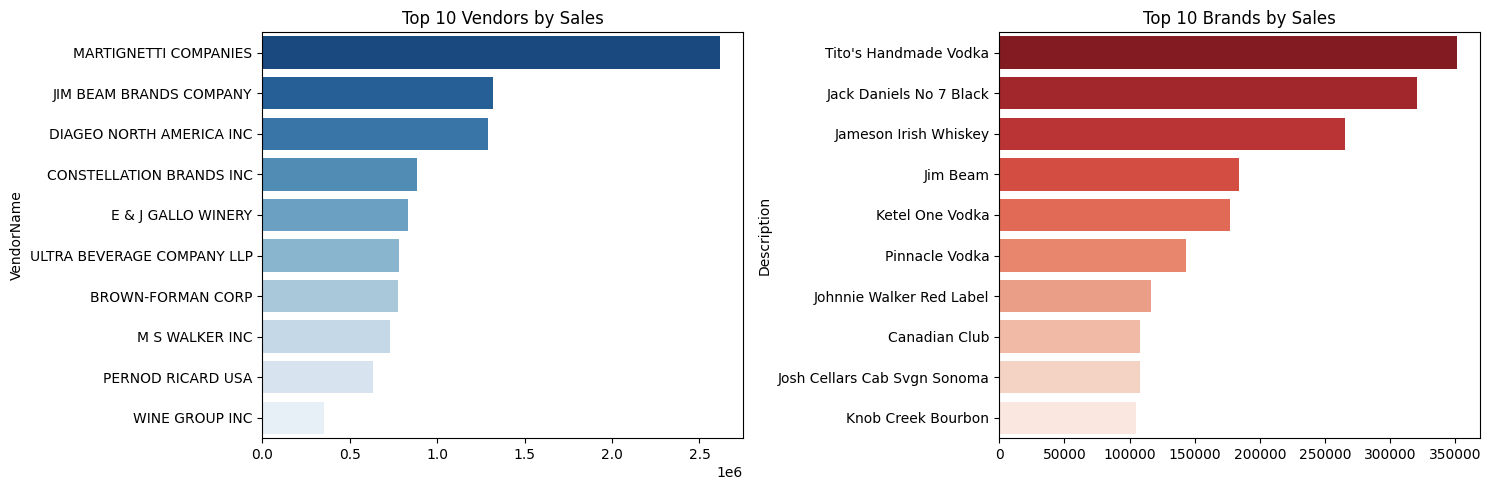

In [ ]:
plt.figure(figsize=(15, 5))

# Plot for Top Vendors
plt.subplot(1, 2, 1)
ax1 = sns.barplot(y=top_vendors.index, x=top_vendors.values, palette="Blues_r")
plt.title("Top 10 Vendors by Sales")



# Plot for Top Brands
plt.subplot(1, 2, 2)
ax2 = sns.barplot(y=top_brands.index.astype(str), x=top_brands.values, palette="Reds_r")
plt.title("Top 10 Brands by Sales")

plt.tight_layout()
plt.show()

In [ ]:
vendor_performance=df.groupby('VendorName').agg({
    'TotalPurchaseDollars': 'sum',
    'GrossProfit':'sum',
    'TotalSalesDollars':'sum'
}).reset_index()

In [ ]:
vendor_performance['PurchaseContribution%'] = vendor_performance['TotalPurchaseDollars']/vendor_performance['TotalPurchaseDollars'].sum()
vendor_performance

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars,PurchaseContribution%
0,ATLANTIC IMPORTING COMPANY,4541.16,1604.72,6145.88,0.000469
1,BACARDI USA INC,204895.88,111021.92,315917.80,0.021148
2,BANFI PRODUCTS CORP,130099.38,73222.42,203321.80,0.013428
3,BLACK PRINCE DISTILLERY INC,3236.57,1590.28,4826.85,0.000334
4,BROWN-FORMAN CORP,554889.35,221750.25,776639.60,0.057272
...,...,...,...,...,...
70,VRANKEN AMERICA,6771.39,4672.83,11444.22,0.000699
71,WESTERN SPIRITS BEVERAGE CO,14361.51,5260.84,19622.35,0.001482
72,WILLIAM GRANT & SONS INC,164106.47,62105.78,226212.25,0.016938
73,WINE GROUP INC,211645.24,141518.56,353163.80,0.021845


In [ ]:
vendor_performance=vendor_performance.sort_values('PurchaseContribution%',ascending = False)
vendor_performance['PurchaseContribution%'] = vendor_performance['PurchaseContribution%']*100

In [ ]:
top_vendors = vendor_performance.head(10)
top_vendors

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars,PurchaseContribution%
35,MARTIGNETTI COMPANIES,1672776.29,945742.83,2618519.12,17.265285
26,JIM BEAM BRANDS COMPANY,974320.10,346260.15,1320580.25,10.056284
14,DIAGEO NORTH AMERICA INC,915369.86,373490.79,1288860.65,9.447839
4,BROWN-FORMAN CORP,554889.35,221750.25,776639.60,5.727199
10,CONSTELLATION BRANDS INC,543802.42,339707.68,883510.10,5.612767
66,ULTRA BEVERAGE COMPANY LLP,523205.24,261200.36,784405.60,5.400177
18,E & J GALLO WINERY,517232.14,315495.36,832727.50,5.338526
32,M S WALKER INC,476013.72,252041.08,728054.80,4.913097
43,PERNOD RICARD USA,450702.92,182089.13,632792.05,4.651856
73,WINE GROUP INC,211645.24,141518.56,353163.80,2.184461


In [ ]:
top_vendors['PurchaseContribution%'].sort_values()


,PurchaseContribution%
73,2.184461
43,4.651856
32,4.913097
18,5.338526
66,5.400177
10,5.612767
4,5.727199
14,9.447839
26,10.056284
35,17.265285


In [ ]:
top_vendors['CumulativeContribution%'] = top_vendors['PurchaseContribution%'].cumsum()
top_vendors['CumulativeContribution%']

,CumulativeContribution%
35,17.265285
26,27.321569
14,36.769408
4,42.496607
10,48.109374
66,53.509551
18,58.848077
32,63.761174
43,68.413030
73,70.597491


In [ ]:
pd.set_option('display.float_format', lambda x: f'{x: .8f}')

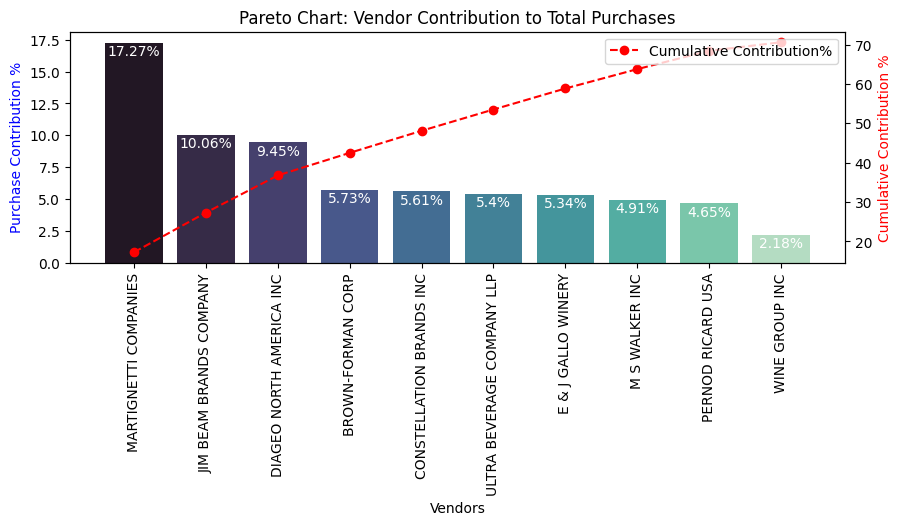

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 3))

# Bar plot for Purchase Contribution%
sns.barplot(
    x=top_vendors['VendorName'],
    y=top_vendors['PurchaseContribution%'],
    palette="mako",
    ax=ax1
)

for i, value in enumerate(top_vendors['PurchaseContribution%']):
    ax1.text(i, value - 1, str(round(value,2)) + '%',
             ha='center', fontsize=10, color='white')

# Line Plot for Cumulative Contribution%
ax2 = ax1.twinx()
ax2.plot(
    top_vendors['VendorName'],
    top_vendors['CumulativeContribution%'],
    color='red',
    marker='o',
    linestyle='dashed',
    label='Cumulative Contribution%'
)

ax1.set_xticklabels(top_vendors['VendorName'], rotation=90)
ax1.set_ylabel('Purchase Contribution %', color='blue')
ax2.set_ylabel('Cumulative Contribution %', color='red')
ax1.set_xlabel('Vendors')
ax1.set_title('Pareto Chart: Vendor Contribution to Total Purchases')


ax2.legend(loc='upper right')

plt.show()

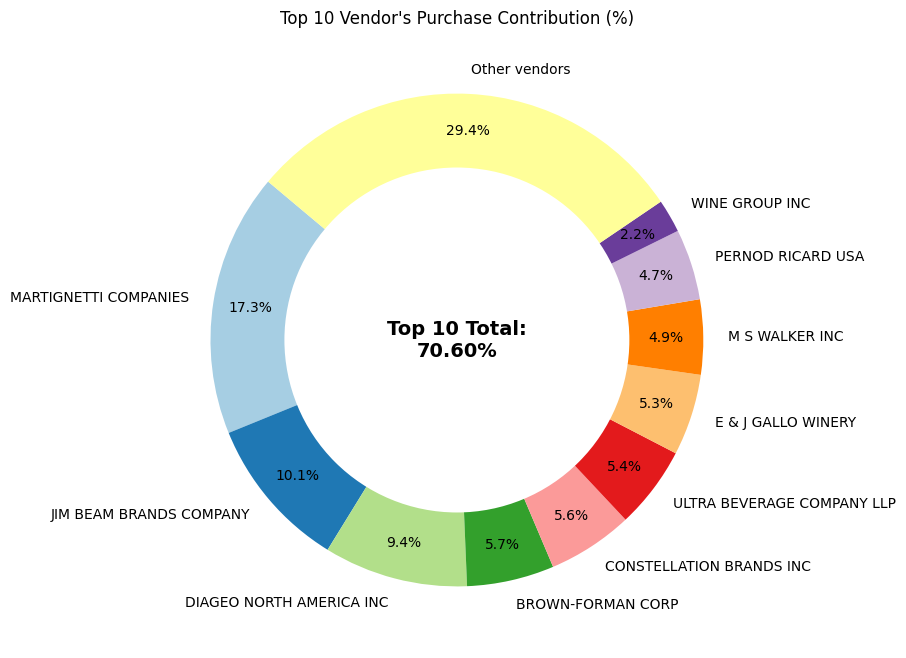

In [ ]:
vendors = list(top_vendors['VendorName'].values)
purchase_contributions = list(top_vendors['PurchaseContribution%'].values)
total_contribution = sum(purchase_contributions)
remaining_contribution = 100 - total_contribution
vendors.append("Other vendors")
purchase_contributions.append(remaining_contribution)
fig,ax = plt.subplots(figsize=(8,8))
wedges, texts, autotexts = ax.pie(
    purchase_contributions,
    labels=vendors,
    autopct='%1.1f%%',
    startangle=140,
    pctdistance=0.85,
    colors=plt.cm.Paired.colors
)
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
fig.gca().add_artist(centre_circle)
plt.text(
    0, 0,
    f"Top 10 Total:\n{total_contribution:.2f}%",
    fontsize=14,
    fontweight='bold',
    ha='center',
    va='center'
)
plt.title("Top 10 Vendor's Purchase Contribution (%)")
plt.show()

In [ ]:
df['UnitPurchasePrice'] = df['TotalPurchaseDollars']/df['TotalPurchaseQuantity']
df

,VendorNumber,VendorName,Description,Brand,ActualPrice,PurchasePrice,Volume,TotalSalesQuantity,TotalSalesDollars,TotalSalesPrice,TotalExciseTax,TotalPurchaseQuantity,TotalPurchaseDollars,TotalFreightCost,GrossProfit,ProfitMargin,StockTurnover,SalesToPurchaseRatio,UnitPurchasePrice
0,388,ATLANTIC IMPORTING COMPANY,Glendalough Double Barrel,2034,32.99000000,21.32000000,750.00000000,212,6145.88000000,6145.88000000,167.48000000,213,4541.16000000,846.96000000,1604.72000000,26.11050004,0.99530516,1.35337227,21.32000000
1,480,BACARDI USA INC,Grey Goose Vodka,126,32.99000000,20.14000000,1000.00000000,1155,38103.45000000,23587.85000000,1212.75000000,1166,23483.24000000,1160721.51000000,14620.21000000,38.36978016,0.99056604,1.62258061,20.14000000
2,480,BACARDI USA INC,B & B Dom VAP,1020,28.99000000,18.11000000,750.00000000,55,1374.45000000,1374.45000000,43.45000000,56,1014.16000000,89286.27000000,360.29000000,26.21339445,0.98214286,1.35525953,18.11000000
3,480,BACARDI USA INC,Grey Goose Glass Pack,1330,49.99000000,38.27000000,1750.00000000,110,6378.90000000,6378.90000000,202.40000000,111,4247.97000000,178572.54000000,2130.93000000,33.40591638,0.99099099,1.50163490,38.27000000
4,480,BACARDI USA INC,Bonnie Rose Spiced Apple,2200,19.99000000,10.78000000,750.00000000,110,1648.90000000,1648.90000000,86.90000000,111,1196.58000000,178572.54000000,452.32000000,27.43162108,0.99099099,1.37801066,10.78000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1447,90058,ZORVINO VINEYARDS,Zorvino Vyds Pearz,22297,9.99000000,6.75000000,750.00000000,330,3296.70000000,3296.70000000,36.30000000,332,2241.00000000,2692.08000000,1055.70000000,32.02293202,0.99397590,1.47108434,6.75000000
1448,90058,ZORVINO VINEYARDS,Zorvino Vyds Sangiovese,22298,12.49000000,8.06000000,750.00000000,110,1373.90000000,1373.90000000,12.10000000,111,894.66000000,897.36000000,479.24000000,34.88172356,0.99099099,1.53566718,8.06000000
1449,90058,ZORVINO VINEYARDS,Zorvino Vyds Mango Magnifico,25125,12.49000000,8.55000000,750.00000000,55,686.95000000,686.95000000,6.05000000,55,470.25000000,448.68000000,216.70000000,31.54523619,1.00000000,1.46081871,8.55000000
1450,90058,ZORVINO VINEYARDS,Zorvino Vyds Peachez,25126,9.99000000,6.62000000,750.00000000,55,549.45000000,549.45000000,6.05000000,55,364.10000000,448.68000000,185.35000000,33.73373373,1.00000000,1.50906344,6.62000000


In [ ]:
df["OrderSize"] = pd.qcut(df['TotalPurchaseQuantity'], q=3, labels=['Small','Medium','Large'])
df[["OrderSize","TotalPurchaseQuantity"]]

,OrderSize,TotalPurchaseQuantity
0,Medium,213
1,Large,1166
2,Small,56
3,Small,111
4,Small,111
...,...,...
1447,Medium,332
1448,Small,111
1449,Small,55
1450,Small,55


In [ ]:
df.groupby("OrderSize")[['UnitPurchasePrice']].mean()

,UnitPurchasePrice
OrderSize,
Small,17.93170341
Medium,12.38607595
Large,8.67674322


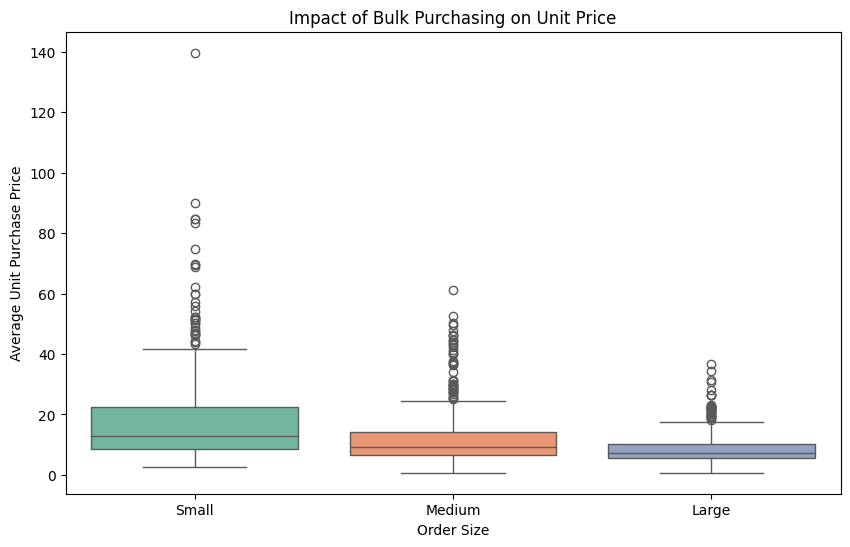

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="OrderSize", y="UnitPurchasePrice", palette="Set2")
plt.title("Impact of Bulk Purchasing on Unit Price")
plt.xlabel("Order Size")
plt.ylabel("Average Unit Purchase Price")
plt.show()

- Vendors buying in bulk (Large Order Size) get the lowest unit price , meaning higher margins if they can manage inventory efficiently.
- The price difference between Small and Large orders is substantial (\~72% reduction in unit price).
- This suggests that bulk pricing strategies successfully encourage vendors to purchase in larger volumes, leading to higher overall sales despite lower per-unit revenue.

Slow moving stock and excess stock

In [ ]:
df[df['StockTurnover']<1].groupby('VendorName')[['StockTurnover']].mean().sort_values(by='StockTurnover',ascending=True).head(10)

,StockTurnover
VendorName,
FLAG HILL WINERY & VINEYARD,0.98833337
ZORVINO VINEYARDS,0.98903658
VINEXTRA INC,0.98950747
Dunn Wine Brokers,0.99009901
MARSALLE COMPANY,0.99009981
DISARONNO INTERNATIONAL LLC,0.99009981
STELLAR IMPORTING CO LLC,0.99029126
EDRINGTON AMERICAS,0.99033325
FREDERICK WILDMAN & SONS,0.99039321


Unsold inventory stock and capital locked

In [ ]:
df["UnsoldInventoryValue"] = (df['TotalPurchaseQuantity']-df['TotalSalesQuantity'])*df['PurchasePrice']
df["UnsoldInventoryValue"].sum()

np.float64(72315.98000000001)

In [ ]:
inventory_value_per_vendor = df.groupby("VendorName")[["UnsoldInventoryValue"]].sum().reset_index()
inventory_value_per_vendor = inventory_value_per_vendor.sort_values(by = 'UnsoldInventoryValue',ascending = False)
inventory_value_per_vendor["UnsoldInventoryValue"].head(10)

,UnsoldInventoryValue
35,12677.27000000
26,7139.05000000
14,7130.66000000
10,4201.27000000
4,3905.40000000
18,3753.24000000
66,3713.74000000
32,3370.12000000
43,3083.77000000
1,1661.53000000


95% confidence intervals for profit margin

In [ ]:
top_threshold = df["TotalSalesDollars"].quantile(0.75)
low_threshold = df["TotalSalesDollars"].quantile(0.25)

In [ ]:
top_vendors = df[df['TotalSalesDollars'] >= top_threshold]['ProfitMargin'].dropna()
low_vendors = df[df['TotalSalesDollars'] <= low_threshold]['ProfitMargin'].dropna()

In [ ]:
top_vendors


,ProfitMargin
1,38.36978016
8,43.22417295
9,34.47283641
13,33.18768544
16,26.75661440
...,...
1396,26.00880579
1398,20.67985121
1415,31.41199226
1433,31.56050299


In [ ]:
def confidence_interval(data, confidence=0.95):
   mean_val = np.mean(data)
   std_err = np.std(data, ddof=1)/np.sqrt(len(data))
   t_critical = stats.t.ppf((1 + confidence)/2, df=len(data) - 1)
   margin_of_error = t_critical * std_err
   return mean_val,mean_val - margin_of_error,mean_val + margin_of_error


Top Vendors 95% CI: (33.02, 34.69), Mean: 33.85
Low Vendors 95% CI: (34.84, 36.62), Mean: 35.73


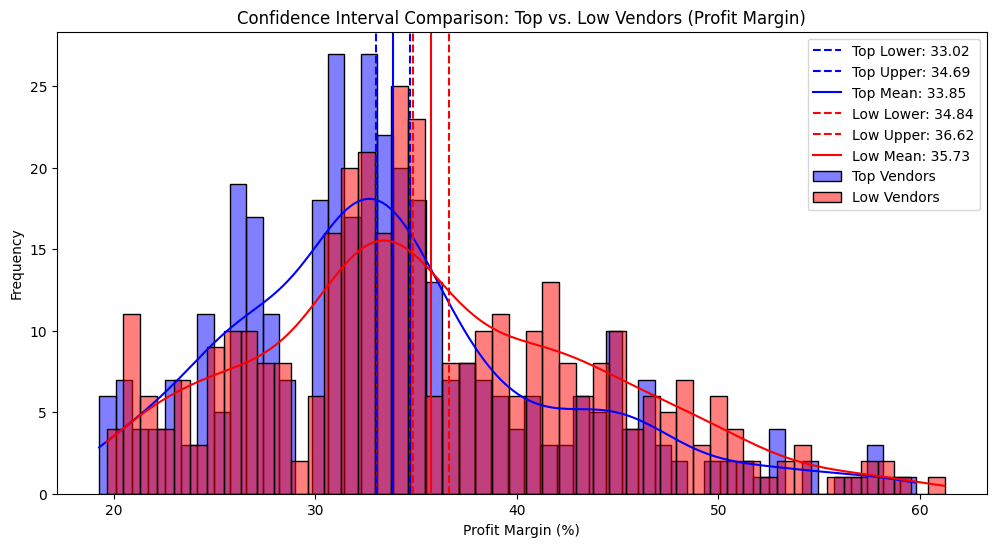

In [ ]:
top_mean, top_lower, top_upper = confidence_interval(top_vendors)
low_mean, low_lower, low_upper = confidence_interval(low_vendors)
print(f"Top Vendors 95% CI: ({top_lower:.2f}, {top_upper:.2f}), Mean: {top_mean:.2f}")
print(f"Low Vendors 95% CI: ({low_lower:.2f}, {low_upper:.2f}), Mean: {low_mean:.2f}")
plt.figure(figsize=(12, 6))
sns.histplot(top_vendors, kde=True, color="blue", bins=50, alpha=0.5, label="Top Vendors")
plt.axvline(top_lower, color="blue", linestyle="--", label=f"Top Lower: {top_lower:.2f}")
plt.axvline(top_upper, color="blue", linestyle="--", label=f"Top Upper: {top_upper:.2f}")
plt.axvline(top_mean, color="blue", linestyle="-", label=f"Top Mean: {top_mean:.2f}")
sns.histplot(low_vendors, kde=True, color="red", bins=50, alpha=0.5, label="Low Vendors")
plt.axvline(low_lower, color="red", linestyle="--", label=f"Low Lower: {low_lower:.2f}")
plt.axvline(low_upper, color="red", linestyle="--", label=f"Low Upper: {low_upper:.2f}")
plt.axvline(low_mean, color="red", linestyle="-", label=f"Low Mean: {low_mean:.2f}")
plt.title("Confidence Interval Comparison: Top vs. Low Vendors (Profit Margin)")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Frequency")
plt.legend()
plt.show()


- The 95% confidence interval for top-performing vendors (32.90% to 33.89%) overlaps slightly with that of low-performing vendors (33.13% to 33.94%), indicating that the difference in their average profit margins may be small.
- The average profit margins are approximately 33.39% for top-performing vendors and 33.53% for low-performing vendors. This suggests that both groups maintain similar average profit margins despite differences in sales performance.
- **For high-performing vendors:** Focus on maintaining sales volume while exploring cost optimization opportunities to improve profitability.
- **For low-performing vendors:** Since their average profit margins are similar to those of top-performing vendors, investigate other factors, such as sales volume, product demand, pricing, and distribution efficiency, to understand their lower sales performance.

In [ ]:
import shutil
from google.colab import files

# Compress all plots into a ZIP file
shutil.make_archive(
    "analytics_plots",
    "zip",
    "analytics_plots"
)

# Download the ZIP file
files.download("analytics_plots.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
df.to_excel("final_table_3.xlsx", index=False)

# Download the Excel file to your computer
from google.colab import files
files.download("final_table_3.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1452 entries, 0 to 1451
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   VendorNumber           1452 non-null   int64   
 1   VendorName             1452 non-null   object  
 2   Description            1452 non-null   object  
 3   Brand                  1452 non-null   int64   
 4   ActualPrice            1452 non-null   float64 
 5   PurchasePrice          1452 non-null   float64 
 6   Volume                 1452 non-null   float64 
 7   TotalSalesQuantity     1452 non-null   int64   
 8   TotalSalesDollars      1452 non-null   float64 
 9   TotalSalesPrice        1452 non-null   float64 
 10  TotalExciseTax         1452 non-null   float64 
 11  TotalPurchaseQuantity  1452 non-null   int64   
 12  TotalPurchaseDollars   1452 non-null   float64 
 13  TotalFreightCost       1452 non-null   float64 
 14  GrossProfit            1452 non-null   f